# 05 - Training

Training of the convolutional-recurrent classifier (`wqu.models.cred`) on one representation, with the parameters of
the `training` and `model` sections of `configs/default.yaml`:
- input standardized per frequency with mean and standard deviation of the training records;
- weighted BCE loss, bad-class weight `n_good / n_bad` of the training records;
- Adam, learning rate reduced on plateau of the validation loss, early stopping, best model kept;
- per-epoch history (loss, AUC, balanced accuracy, ECE, learning rate) and its figures;
- MC dropout predictions on the validation set.

Every run writes to its own folder `training.runs_dir/<representation>_<date>_<time>/`: copy of the configuration,
normalization statistics, `history.csv` (updated at every epoch), `best_model.pt`, figures and validation predictions.

The training metrics are computed on the outputs produced while training (dropout active, weights changing within the
epoch), the validation metrics on a deterministic pass at the end of the epoch: with strong dropout the training loss can
stay above the validation loss without any anomaly.

## 0. Setup

In [1]:
from pathlib import Path

import pandas as pd

from wqu.config import load_config
from wqu.data.loading import CV_COMPONENTS
from wqu.data.splitting import SPLIT_COLUMN, TRAIN, VALIDATION, attach_split, load_split
from wqu.models.cred import build_model
from wqu.models.loss import bad_class_weight, weighted_bce_loss
from wqu.models.uncertainty import prediction_table
from wqu.preprocessing.pipeline import FEATURE_INDEX_COLUMN, feature_file_path, read_feature_records
from wqu.training.data import FeatureDataset, frequency_statistics, make_loader
from wqu.training.metrics import classification_metrics
from wqu.training.trainer import VALIDATION_PREDICTIONS_FILE, create_run_dir, fit, select_device, set_seed
from wqu.visualization import apply_plot_style, plot_training_curve, plot_training_history, save_figure
import matplotlib.pyplot as plt

CONFIG_PATH = Path("..") / "configs" / "default.yaml"

config = load_config(CONFIG_PATH)
columns = config.columns
training = config.training
apply_plot_style()
set_seed(training.random_seed)
device = select_device(training.device)

features_path = feature_file_path(config.preprocessing, training.feature_source)
records = read_feature_records(features_path, columns.text)
records[SPLIT_COLUMN] = attach_split(records, load_split(config.split.output_file, columns), columns)
print(f"Feature file: {features_path} ({len(records):,} records); representation: {training.representation}; "
      f"device: {device}")

/Users/giulianaparadiso/miniconda3/envs/wqu/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Feature file: /Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/data/processed/seisbench/features.h5 (100,249 records); representation: spectrogram; device: mps


## 1. Data

Per-frequency statistics from the training records only, bad-class weight from the training labels.

In [2]:
train_records = records[records[SPLIT_COLUMN] == TRAIN]
validation_records = records[records[SPLIT_COLUMN] == VALIDATION]
statistics = frequency_statistics(features_path, training.representation, train_records[FEATURE_INDEX_COLUMN].to_numpy())
bad_weight = bad_class_weight(train_records[columns.label].to_numpy())

run_dir = create_run_dir(training.runs_dir, training.representation, CONFIG_PATH)
statistics.save(run_dir / "normalization.npz")


def loader_for(subset: pd.DataFrame, shuffle: bool):
    """Loader of standardized images for a subset of the records."""
    dataset = FeatureDataset(features_path, training.representation, subset[FEATURE_INDEX_COLUMN].to_numpy(),
                             subset[columns.label].to_numpy(), statistics)
    return make_loader(dataset, training.batch_size, shuffle, training.num_workers, training.random_seed)


train_loader = loader_for(train_records, shuffle=True)
validation_loader = loader_for(validation_records, shuffle=False)
summary = records.groupby(SPLIT_COLUMN)[columns.label].agg(records="size", bad_rate="mean")
print(f"Run folder: {run_dir}")
print(f"Bad-class weight: {bad_weight:.3f}")
summary.round(3)

Run folder: /Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/runs/spectrogram_20261111_144914
Bad-class weight: 1.782


,records,bad_rate
split,,
train,80193,0.359
validation,20056,0.359


## 2. Training

The progress is printed at every epoch; `history.csv` in the run folder is rewritten at every epoch, so the run can be
followed from outside the notebook.

In [3]:
model = build_model(config.model, len(CV_COMPONENTS), len(statistics.mean))
result = fit(model, train_loader, validation_loader, weighted_bce_loss(bad_weight), training, bad_weight, run_dir, device)
history = result.history
print(f"Best epoch: {result.best_epoch} of {len(history)}; stopped early: {result.stopped_early}; "
      f"total time {history['seconds'].sum() / 60:.1f} min")
history.round(4)

epoch   1  train loss 0.5786  validation loss 0.5543  validation AUC 0.8832  lr 1.0e-03  97 s  (best)
epoch   2  train loss 0.5437  validation loss 0.5557  validation AUC 0.8818  lr 1.0e-03  95 s
epoch   3  train loss 0.5408  validation loss 0.5392  validation AUC 0.8898  lr 1.0e-03  93 s  (best)
epoch   4  train loss 0.5309  validation loss 0.5956  validation AUC 0.8627  lr 1.0e-03  93 s
epoch   5  train loss 0.5331  validation loss 0.5256  validation AUC 0.8965  lr 1.0e-03  95 s  (best)
epoch   6  train loss 0.5284  validation loss 0.5377  validation AUC 0.8944  lr 1.0e-03  93 s
epoch   7  train loss 0.5282  validation loss 0.5266  validation AUC 0.8957  lr 1.0e-03  93 s
epoch   8  train loss 0.5258  validation loss 0.5308  validation AUC 0.8931  lr 1.0e-03  92 s
epoch   9  train loss 0.5244  validation loss 0.5345  validation AUC 0.8948  lr 1.0e-03  92 s
epoch  10  train loss 0.5108  validation loss 0.5078  validation AUC 0.9022  lr 5.0e-04  92 s  (best)
epoch  11  train loss 0.5059

,epoch,learning_rate,train_loss,validation_loss,train_auc,train_balanced_accuracy,train_ece,validation_auc,validation_balanced_accuracy,validation_ece,seconds
0,1,0.0010,0.5786,0.5543,0.8713,0.7967,0.0151,0.8832,0.8036,0.0237,96.8469
1,2,0.0010,0.5437,0.5557,0.8873,0.8121,0.0126,0.8818,0.8027,0.0200,94.6078
2,3,0.0010,0.5408,0.5392,0.8887,0.8137,0.0139,0.8898,0.8099,0.0241,93.4762
3,4,0.0010,0.5309,0.5956,0.8929,0.8185,0.0124,0.8627,0.7834,0.0202,92.8985
4,5,0.0010,0.5331,0.5256,0.8920,0.8159,0.0124,0.8965,0.8140,0.0267,94.8913
5,6,0.0010,0.5284,0.5377,0.8939,0.8185,0.0122,0.8944,0.8150,0.0397,93.1320
6,7,0.0010,0.5282,0.5266,0.8942,0.8178,0.0106,0.8957,0.8172,0.0212,92.9039
7,8,0.0010,0.5258,0.5308,0.8950,0.8191,0.0107,0.8931,0.8098,0.0197,92.3568
8,9,0.0010,0.5244,0.5345,0.8957,0.8197,0.0114,0.8948,0.8113,0.0407,92.2876
9,10,0.0005,0.5108,0.5078,0.9013,0.8249,0.0113,0.9022,0.8216,0.0079,92.2662


## 3. Training curves

Overview (loss and learning rate on top; AUC, balanced accuracy and ECE below) and the loss alone. The dashed line marks
the epoch of the saved model.

PosixPath('/Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/runs/spectrogram_20261111_144914/figures/training_loss.pdf')

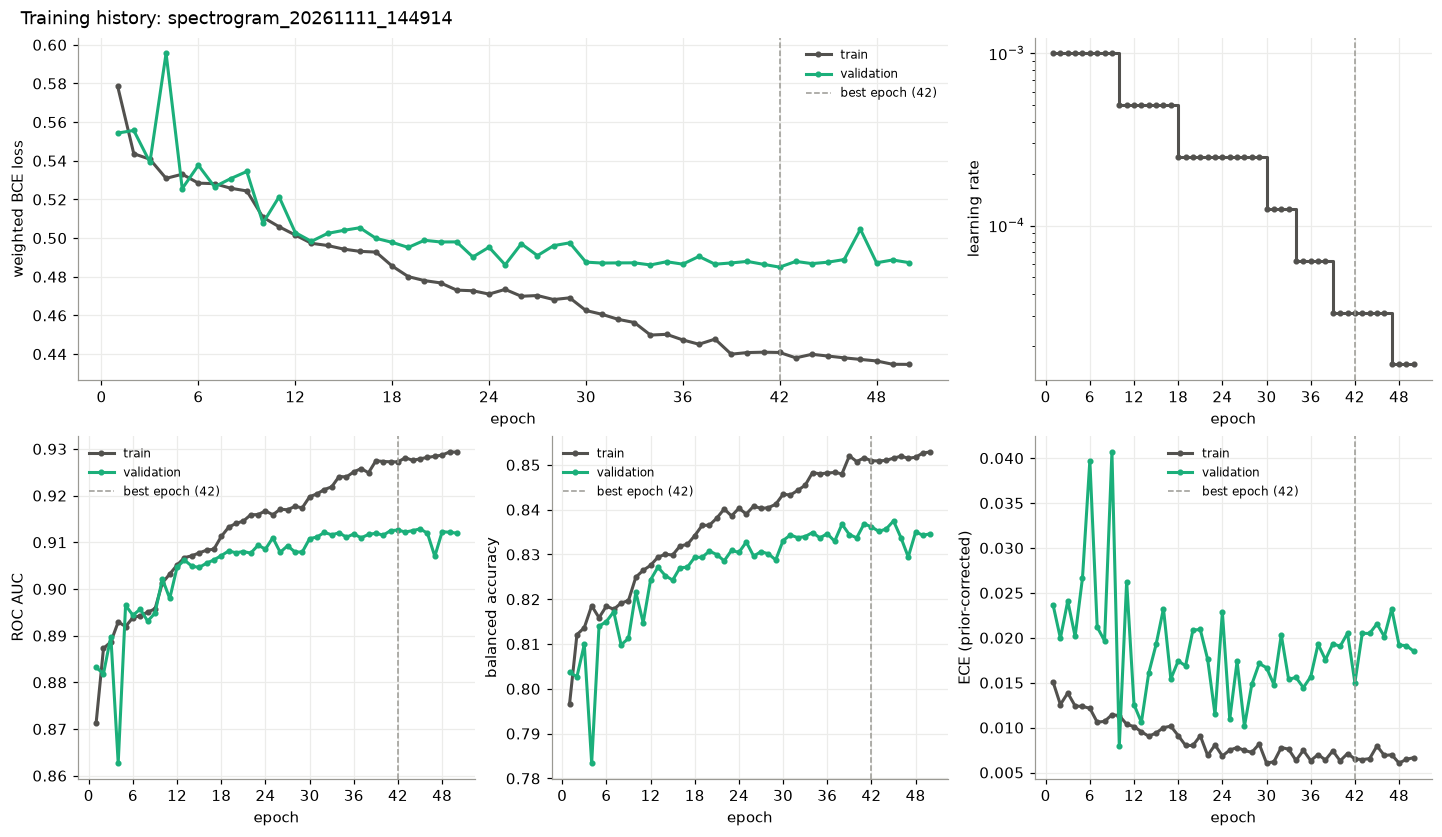

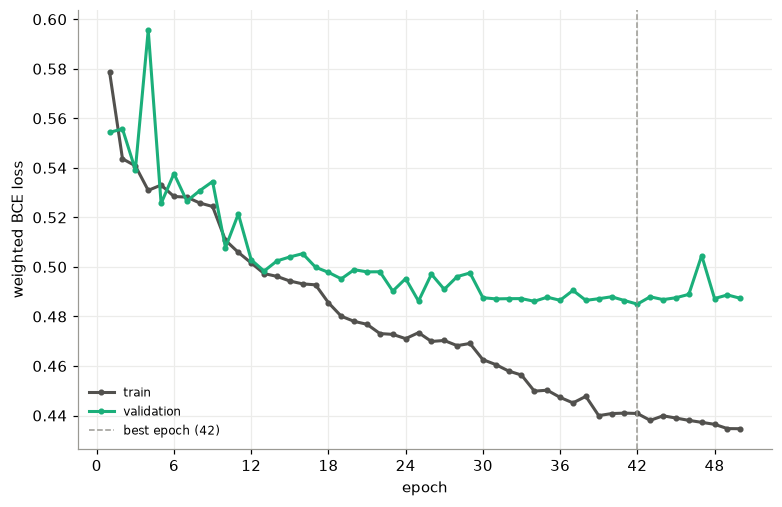

In [4]:
figures_dir = run_dir / "figures"
overview = plot_training_history(history, result.best_epoch, f"Training history: {run_dir.name}")
save_figure(overview, figures_dir / "training_history.png")
save_figure(overview, figures_dir / "training_history.pdf")

loss_figure, loss_ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
plot_training_curve(history, "loss", result.best_epoch, loss_ax)
save_figure(loss_figure, figures_dir / "training_loss.png")
save_figure(loss_figure, figures_dir / "training_loss.pdf")

## 4. Validation predictions with MC dropout

For every validation record: probability of the bad class from the deterministic pass (dropout off) and its entropy;
from `model.mc_samples` stochastic passes, mean and standard deviation of the probability, predictive entropy and its
split into aleatoric part and mutual information (epistemic part); both probabilities also corrected to the class
frequencies of the training set. The table is the input of notebook 06 (evaluation).

In [5]:
predictions = prediction_table(model, validation_loader, config.model.mc_samples, device, bad_weight)
predictions.insert(0, "record", validation_records.index.to_numpy())
predictions.insert(1, columns.label, validation_records[columns.label].to_numpy())
predictions.to_csv(run_dir / VALIDATION_PREDICTIONS_FILE, index=False)

labels = predictions[columns.label].to_numpy()
comparison = {}
for name, probability in (("deterministic", "probability_deterministic"), ("mc_dropout", "probability_mean")):
    metrics = classification_metrics(predictions[probability].to_numpy(), labels, training.calibration_bins)
    metrics["ece"] = classification_metrics(predictions[f"{probability}_corrected"].to_numpy(), labels,
                                            training.calibration_bins)["ece"]
    comparison[name] = metrics
comparison = pd.DataFrame(comparison)
comparison.to_csv(run_dir / "validation_metrics.csv")
comparison.round(4)

,deterministic,mc_dropout
auc,0.9126,0.9140
balanced_accuracy,0.8362,0.8371
ece,0.0150,0.0102


In [6]:
predictions.groupby(columns.label)[["probability_mean", "probability_std", "predictive_entropy",
                                     "mutual_information"]].describe().T.round(4)

label                              0          1
probability_mean   count  12846.0000  7210.0000
                   mean       0.2257     0.7549
                   std        0.2436     0.2539
                   min        0.0015     0.0046
                   25%        0.0419     0.6164
                   50%        0.1200     0.8640
                   75%        0.3435     0.9496
                   max        0.9933     0.9988
probability_std    count  12846.0000  7210.0000
                   mean       0.0596     0.0580
                   std        0.0350     0.0332
                   min        0.0017     0.0019
                   25%        0.0316     0.0334
                   50%        0.0565     0.0542
                   75%        0.0806     0.0763
                   max        0.2616     0.2722
predictive_entropy count  12846.0000  7210.0000
                   mean       0.3677     0.3819
                   std        0.2142     0.2114
                   min        0.0115     0.0093
                   25%        0.1717     0.1941
                   50%        0.3479     0.3686
                   75%        0.5755     0.5873
                   max        0.6931     0.6931
mutual_information count  12846.0000  7210.0000
                   mean       0.0167     0.0154
                   std        0.0118     0.0109
                   min        0.0007     0.0008
                   25%        0.0093     0.0089
                   50%        0.0141     0.0128
                   75%        0.0206     0.0185
                   max        0.1542     0.1639